# [1] 08 Alignment arrays: did the two-year clock exist before InSAR?

```
Created on Thu Sep 24 2026
@author: daniellelindsay
Run in opera_disp_feb13. Seconds.
```

**What this notebook does.** The USGS Bay Area alignment arrays (archive v3.0)
give a 45-year record of surface slip at Tule Pond. Six arrays span the
section; HRKT was surveyed every ~60 days from 1979 to 2007 (annually after),
so it can carry an event detector directly; HGIL is annual throughout.

1. **Arrays and InSAR side by side.** The InSAR fault-parallel stack within
   1 km of each array, tied to the array by the mean offset at the surveys
   inside the InSAR window (a vertical shift only). The survey step that
   brackets each InSAR onset, and the "event" against "quiet" survey
   intervals since 2015.
2. **The HRKT event history.** An event is a survey interval whose step
   exceeds the inter-event rate by a fixed 6 mm (2.3 robust sigma; the
   relative 3 sigma cut at 7.7 mm drops the visually obvious 1986, 1988 and
   1997 steps). Two passes with the same joint model as notebook 04, onsets at
   interval midpoints, and every event must carry positive fitted slip.
3. **Repeat intervals and step sizes** of the array catalogue over its whole
   45 years against the InSAR catalogue, and the merged catalogue's trend.
4. **Threshold sweep** (supplement): the same detector at 3 sigma, 6 mm and 5 mm.

Ported from `Hayward_DISP-S1/analysis/run16_AA_insar_timeseries.py`,
`run18_aa_event_history.py`, `plotting/fig_aa_history.py` and
`plotting/figS_hrkt_threshold_sweep.py`. The forced-period comb tests (run17,
run19) are not in the paper and are not ported.

**Outputs** (`outputs/08_alignment_arrays/`): `hrkt_aa_events.csv`,
`aa_insar_steps.csv`, `hrkt_threshold_sweep.csv`, `08_aa_stats.txt`, registry rows `08_*`.

**Figures**: Fig 3 (a: survey cadence, b: HRKT record with events, c: the
detection statistic, d: repeat intervals and step sizes), the six-array
comparison (supplement), the threshold sweep (supplement).

**What to check.** HRKT: 177 surveys, 14 events of 0.5 to 13 mm (median 7.4),
median repeat interval 2.8 yr against 1.9 yr for the InSAR catalogue; the
quiet interval spanning Loma Prieta (1989); HGIL's surveys since 2015 stepping
~14 mm in event years and ~0 mm in quiet years. The CHECK cell compares every
product with the previous run of this notebook.

In [1]:
# [2]
import os
import warnings

import insar_utils as utils
from TulePond_filepaths import common_paths, params, paths_out, repo_dir

import numpy as np                               # Matrix calculations
import pandas as pd                              # Tables
import matplotlib.pyplot as plt

## [3] Paths and parameters

In [2]:
# [4]
notebook = "08_alignment_arrays"
out_dir = os.path.join(common_paths["out_dir"], notebook)
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

# the products of the previous version of this notebook, for the CHECK cell

stack_km = 1.0                 # half-width of the InSAR stack around each array
site = "HRKT"                  # the array with the dense record
thr_mm = 6.0                   # detection threshold: fixed excess per survey interval (see the sweep)
n_pass = 2                     # detector passes (pass 2 uses the fitted inter-event rate)
dense_window_days = 130        # array events with survey windows up to this (the bimonthly era, to 2006) enter the merged clock;
#                                the annual-survey years after 2006 are treated as unobserved (Dani, 2026-09-24)
win_yr, win_step = 10.0, 1.0   # moving window for the repeat-interval trend (sweep figure)
zoom_t0 = 2015.0               # start of the zoomed panels
loma_prieta = 1989.79
# the six arrays across the section, north -> south (latitudes from the archive summary)
array_lat = {"HAPP": 37.5924, "HGIL": 37.5665, "HRKT": 37.5421, "HHAN": 37.5394, "HUNI": 37.5361, "HPIN": 37.5197}

fp_ts_file = os.path.join(paths_out["03_creep_timeseries"], "fp_ts.csv")
events_file = os.path.join(paths_out["04_event_detection"], "creep_events.csv")
aa_color, insar_color, det_color = "#08306B", "#D55E00", "#0072B2"

REG = utils.Registry(notebook, common_paths, repo_dir)
REG.inputs(fp_ts_file, events_file, common_paths["aa_summary"],
           *[os.path.join(common_paths["aa_dir"], f"{code}.csv") for code in array_lat])

Registry for 08_alignment_arrays: run 6acc0c38, git 083befe+


## [5] Load: the InSAR fault-parallel time series, the InSAR catalogue, the arrays

In [3]:
# [6]
# the fault-parallel time series from 03: lat x decimal year, mm
fp_ts = pd.read_csv(fp_ts_file, index_col=0)
fp_ts.columns = fp_ts.columns.astype(float)
fp_ts.index = fp_ts.index.astype(float)
fp_dates = fp_ts.columns.values.astype(float)

# the InSAR event catalogue from 04, Tule Pond only
creep_events = pd.read_csv(events_file)
insar_events = creep_events[creep_events.segment == "TULEPOND"]
insar_events = insar_events[["onset_yr", "onset_lo", "onset_hi", "amplitude_mm", "amp_lo", "amp_hi"]]
insar_events = insar_events.sort_values("onset_yr").reset_index(drop=True)
insar_events["amp_err"] = (insar_events.amp_hi - insar_events.amp_lo) / 3.92      # 95% bootstrap bounds as 1 sigma, to match the array errors
print("InSAR onsets:", [round(x, 3) for x in insar_events.onset_yr])

# the six arrays: year, cum_mm, std_mm each
arrays = {code: utils.load_aa(common_paths["aa_dir"], code) for code in array_lat}
for code, array in arrays.items():
    print(f"  {code}: {len(array)} surveys {array.year.min():.2f} to {array.year.max():.2f}, "
          f"median spacing {np.median(np.diff(array.year)) * 365.25:.0f} d, "
          f"{array.cum_mm.iloc[-1] / (array.year.max() - array.year.min()):.2f} mm/yr over the record")

InSAR onsets: [2017.099, 2019.186, 2021.107, 2023.08, 2024.984]
  HAPP: 174 surveys 1979.73 to 2024.68, median spacing 64 d, 6.00 mm/yr over the record
  HGIL: 45 surveys 1983.76 to 2024.93, median spacing 365 d, 5.99 mm/yr over the record
  HRKT: 177 surveys 1979.73 to 2024.72, median spacing 63 d, 5.73 mm/yr over the record
  HHAN: 30 surveys 1982.04 to 2024.72, median spacing 367 d, 6.22 mm/yr over the record
  HUNI: 34 surveys 1993.02 to 2024.82, median spacing 364 d, 6.65 mm/yr over the record
  HPIN: 36 surveys 1989.22 to 2024.82, median spacing 370 d, 7.21 mm/yr over the record


## [7] The InSAR stack at each array

The mean of the fault-parallel series of every crossing within `stack_km` of
the array (crossings with fewer than half their dates are left out), tied to
the array by the mean offset at the surveys that fall inside the InSAR window.
A vertical shift only: nothing is fitted.

In [4]:
# [8]
def insar_stack(code, array):
    """(dates, slip_mm, n_crossings) of the InSAR stack at one array, tied to the array."""
    lat = array_lat[code]
    half_width_deg = stack_km / 111.19            # fp_ts is indexed by latitude: 1 km = 1/111.19 deg of latitude
    nearby = fp_ts[(fp_ts.index >= lat - half_width_deg) & (fp_ts.index <= lat + half_width_deg)]
    nearby = nearby[nearby.notna().sum(axis=1) > 0.5 * fp_ts.shape[1]]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        slip = np.nanmean(nearby.values, axis=0)
    ok = np.isfinite(slip)
    dates, slip = fp_dates[ok], slip[ok]
    # tie: the surveys inside the InSAR window, else the last survey against the first InSAR date
    in_window = array[(array.year >= dates.min()) & (array.year <= dates.max())]
    if len(in_window):
        offset = float(np.mean(in_window.cum_mm.values - np.interp(in_window.year.values, dates, slip)))
    else:
        offset = float(array.cum_mm.iloc[-1] - slip[0])
    return dates, slip + offset, len(nearby)


stacks = {code: insar_stack(code, array) for code, array in arrays.items()}

# saved for notebook 09, which draws the combined Fig 3 (HRKT record + onsets over the rain)
stack_rows = []
for code, (insar_dates, insar_slip, n_crossings) in stacks.items():
    stack_rows += [dict(code=code, date=date, slip_mm=slip, n_crossings=n_crossings) for date, slip in zip(insar_dates, insar_slip)]
pd.DataFrame(stack_rows).to_csv(os.path.join(out_dir, "aa_insar_stacks.csv"), index=False)

## [9] The arrays against the InSAR at each site

For each InSAR onset, the array step between the surveys either side of it;
and, since 2015, the median step of survey intervals that contain an InSAR
onset against those that do not. At HGIL, inside the peak zone, the array
steps ~14 mm in event years and ~0 mm between: the array's own statement
of the sawtooth.

In [5]:
# [10]
stats_lines = ["08 ALIGNMENT ARRAYS",
               f"InSAR stack: crossings within +/-{stack_km:g} km of each array; tie: mean offset at surveys inside the InSAR window",
               "InSAR onsets: " + ", ".join(f"{x:.3f}" for x in insar_events.onset_yr), ""]
step_rows = []
for code, array in arrays.items():
    insar_dates, insar_slip, n_crossings = stacks[code]
    in_window = array[(array.year >= insar_dates.min()) & (array.year <= insar_dates.max())]
    stats_lines.append(f"{code} (lat {array_lat[code]}), stack {n_crossings} crossings; array {array.year.min():.2f}-{array.year.max():.2f}, "
                       f"{len(array)} surveys, {array.cum_mm.iloc[-1] / (array.year.max() - array.year.min()):.2f} mm/yr; "
                       f"InSAR {(insar_slip[-1] - insar_slip[0]) / (insar_dates[-1] - insar_dates[0]):.2f} mm/yr, {len(in_window)} surveys in window")
    # the array step across each InSAR onset: last survey before minus first survey after
    for onset in insar_events.onset_yr:
        before, after = array[array.year < onset], array[array.year > onset]
        if len(before) and len(after):
            survey_before, survey_after = before.iloc[-1], after.iloc[0]
            step_mm = survey_after.cum_mm - survey_before.cum_mm
            stats_lines.append(f"    {onset:.3f}: array step {step_mm:+5.1f} mm over {survey_before.year:.2f}-{survey_after.year:.2f} "
                               f"({(survey_after.year - survey_before.year) * 365.25:.0f} d)")
            step_rows.append(dict(code=code, onset=onset, step_mm=step_mm, from_yr=survey_before.year, to_yr=survey_after.year))
        else:
            stats_lines.append(f"    {onset:.3f}: not bracketed by surveys")
    # since zoom_t0: survey intervals that contain an InSAR onset against those that do not
    recent = array[array.year >= zoom_t0].reset_index(drop=True)
    event_steps, quiet_steps = [], []
    for i in range(1, len(recent)):
        step_mm = float(recent.cum_mm.iloc[i] - recent.cum_mm.iloc[i - 1])
        has_event = any(recent.year.iloc[i - 1] < onset < recent.year.iloc[i] for onset in insar_events.onset_yr)
        if has_event:
            event_steps.append(step_mm)
        else:
            quiet_steps.append(step_mm)
    if event_steps and quiet_steps:
        stats_lines.append(f"    intervals since {zoom_t0:.0f}: with an event {np.median(event_steps):+5.1f} mm (median, n = {len(event_steps)}) "
                           f"vs quiet {np.median(quiet_steps):+5.1f} mm (n = {len(quiet_steps)})")
        step_rows.append(dict(code=code, onset=np.nan, step_mm=np.median(event_steps), from_yr=np.nan, to_yr=np.nan, kind="event_median", n=len(event_steps)))
        step_rows.append(dict(code=code, onset=np.nan, step_mm=np.median(quiet_steps), from_yr=np.nan, to_yr=np.nan, kind="quiet_median", n=len(quiet_steps)))
    stats_lines.append("")
aa_steps = pd.DataFrame(step_rows)
aa_steps.to_csv(os.path.join(out_dir, "aa_insar_steps.csv"), index=False)
print("\n".join(stats_lines))

08 ALIGNMENT ARRAYS
InSAR stack: crossings within +/-1 km of each array; tie: mean offset at surveys inside the InSAR window
InSAR onsets: 2017.099, 2019.186, 2021.107, 2023.080, 2024.984

HAPP (lat 37.5924), stack 14 crossings; array 1979.73-2024.68, 174 surveys, 6.00 mm/yr; InSAR 5.57 mm/yr, 8 surveys in window
    2017.099: array step  +7.4 mm over 2016.76-2017.79 (376 d)
    2019.186: array step  +7.4 mm over 2018.80-2019.82 (371 d)
    2021.107: array step +11.3 mm over 2019.82-2021.87 (749 d)
    2023.080: array step  +7.5 mm over 2022.79-2023.86 (391 d)
    2024.984: not bracketed by surveys
    intervals since 2015: with an event  +7.4 mm (median, n = 4) vs quiet  +6.6 mm (n = 4)

HGIL (lat 37.5665), stack 23 crossings; array 1983.76-2024.93, 45 surveys, 5.99 mm/yr; InSAR 6.04 mm/yr, 8 surveys in window
    2017.099: array step +18.1 mm over 2016.76-2017.83 (388 d)
    2019.186: array step +11.4 mm over 2018.80-2019.82 (371 d)
    2021.107: array step +14.3 mm over 2019.82-2021

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-28/figS_tulepond_arrays_insar_ap30-150m_coh0.7_mp5_sw200m_stack1km.png


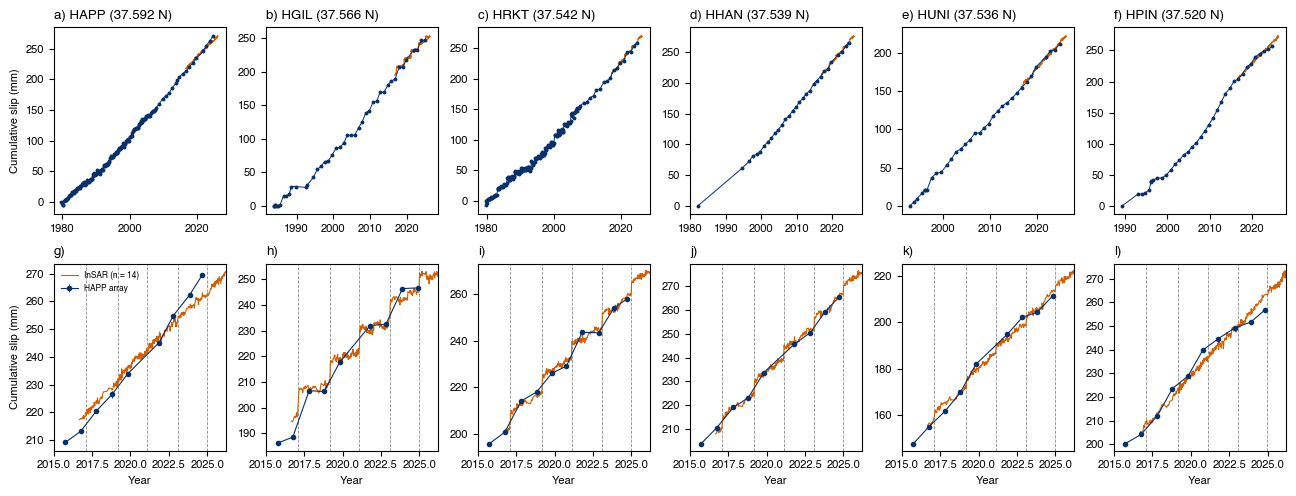

In [6]:
# [11]
# supplement figure: the six arrays against the InSAR, whole record on top, since 2015 below
utils.mpl_paper_style(base=8)          # Helvetica, 8 pt, editable PDF text
fig, axes = plt.subplots(2, len(array_lat), figsize=(13.0, 5.0))
for i, (code, array) in enumerate(arrays.items()):
    insar_dates, insar_slip, n_crossings = stacks[code]
    # whole record
    ax = axes[0, i]
    ax.errorbar(array.year, array.cum_mm, yerr=array.std_mm, fmt="o", ms=1.8, color=aa_color, ecolor=aa_color, elinewidth=0.4, lw=0.7, ls="-")
    ax.plot(insar_dates, insar_slip, "-", lw=0.8, color=insar_color)
    ax.set_title(f"{'abcdef'[i]}) {code} ({array_lat[code]:.3f} N)", loc="left")
    if i == 0:
        ax.set_ylabel("Cumulative slip (mm)")
    # since zoom_t0
    ax = axes[1, i]
    recent = array.year >= zoom_t0
    ax.errorbar(array.year[recent], array.cum_mm[recent], yerr=array.std_mm[recent], fmt="o", ms=3, color=aa_color, ecolor=aa_color,
                elinewidth=0.6, lw=0.8, ls="-", label=f"{code} array")
    ax.plot(insar_dates, insar_slip, "-", lw=0.8, color=insar_color, label=f"InSAR (n = {n_crossings})")
    for onset in insar_events.onset_yr:
        ax.axvline(onset, color="0.55", lw=0.6, ls="--", zorder=0)
    ax.set_xlim(zoom_t0, 2026.2)
    ax.set_xlabel("Year")
    y_lo = min(np.nanmin(insar_slip), array.cum_mm[recent].min())
    y_hi = max(np.nanmax(insar_slip), array.cum_mm[recent].max())
    ax.set_ylim(y_lo - 3, y_hi + 3)
    if i == 0:
        ax.set_ylabel("Cumulative slip (mm)")
        ax.legend(fontsize=6, loc="upper left", frameon=False)
    ax.set_title(f"{'ghijkl'[i]})", loc="left")
fig.tight_layout()
f_arrays = os.path.join(fig_dir, f"figS_tulepond_arrays_insar_{params}_stack{stack_km:g}km.png")
fig.savefig(f_arrays, dpi=300)
fig.savefig(f_arrays.replace(".png", ".pdf"))
print("Saved figure to:", f_arrays)
plt.show()

## [12] The HRKT event history

Detection on survey intervals: `excess = (cum_i - cum_{i-1}) - rate * (t_i - t_{i-1})`
beats `thr_mm`. Pass 1 uses the global rate; the flagged intervals are
fitted with the joint model (constant + rate + annual + a step per event at
the interval midpoints), any event the model gives non-positive slip is
dropped and the fit repeated; pass 2 uses the fitted inter-event rate.
The three functions below are used again by the threshold sweep.

In [7]:
# [13]
def design_matrix(dates, onsets):
    """Columns: constant, rate, annual sin and cos, then one step per onset."""
    columns = [np.ones_like(dates), dates - dates.mean(), np.sin(2 * np.pi * dates), np.cos(2 * np.pi * dates)]
    columns += [(dates > onset).astype(float) for onset in onsets]
    return np.column_stack(columns)


def detect_intervals(survey_yr, cum_slip, rate_mm_yr, threshold_mm):
    """Survey intervals whose excess step beats the threshold, as (i_start, i_end)
    index pairs; consecutive flagged intervals are merged into one. Also returns
    the excess of every interval."""
    excess = np.diff(cum_slip) - rate_mm_yr * np.diff(survey_yr)
    events = []
    for i in np.where(excess > threshold_mm)[0]:
        if events and i == events[-1][1]:            # continues the previous flagged interval
            events[-1][1] = i + 1
        else:
            events.append([i, i + 1])
    return [(i_start, i_end) for i_start, i_end in events], excess


def run_detector(survey_yr, cum_slip, threshold_mm):
    """Two passes of detection + positive-step joint fit.
    Returns (catalogue, excess, inter_event_rate, coef, design_G)."""
    inter_event_rate = float(np.polyfit(survey_yr, cum_slip, 1)[0])          # pass 1: the global rate
    for _ in range(n_pass):
        events, excess = detect_intervals(survey_yr, cum_slip, inter_event_rate, threshold_mm)
        # fit the joint model; drop the weakest event while any fitted step is not positive
        for _ in range(len(events) + 1):
            onsets = [0.5 * (survey_yr[i_start] + survey_yr[i_end]) for i_start, i_end in events]
            design_G = design_matrix(survey_yr, onsets)
            coef, *_ = np.linalg.lstsq(design_G, cum_slip, rcond=None)
            if len(events) == 0 or coef[4:].min() > 0:
                break
            i_start, i_end = events.pop(int(np.argmin(coef[4:])))
            print(f"      dropped {survey_yr[i_start]:.2f}-{survey_yr[i_end]:.2f}: fitted slip {coef[4:].min():.1f} mm, not positive")
        inter_event_rate = float(coef[1])                                     # pass 2 uses the fitted rate
    residual = cum_slip - np.dot(design_G, coef)                  # np.dot(G, coef) = the model at every survey
    variance = float(np.sum(residual ** 2) / (len(survey_yr) - design_G.shape[1]))
    amp_err = np.sqrt(variance * np.diag(np.linalg.inv(np.dot(design_G.T, design_G))))[4:]
    catalogue = pd.DataFrame([dict(onset_yr=onset, onset_lo=survey_yr[i_start], onset_hi=survey_yr[i_end],
                                   window_days=(survey_yr[i_end] - survey_yr[i_start]) * 365.25,
                                   amplitude_mm=float(amplitude), amp_err=float(err))
                              for (i_start, i_end), onset, amplitude, err in zip(events, onsets, coef[4:], amp_err)])
    return catalogue, excess, inter_event_rate, coef, design_G


hrkt = arrays[site]
survey_yr = hrkt.year.values
cum_slip = hrkt.cum_mm.values
hrkt_events, excess, inter_event_rate, coef, design_G = run_detector(survey_yr, cum_slip, thr_mm)
excess_sigma = utils.robust_sigma(excess)
annual_mm = float(np.hypot(coef[2], coef[3]))
rms_mm = float(np.sqrt(np.mean((cum_slip - np.dot(design_G, coef)) ** 2)))
hrkt_events.round(4).to_csv(os.path.join(out_dir, f"{site.lower()}_aa_events.csv"), index=False)

print(f"{site}: {len(survey_yr)} surveys {survey_yr.min():.2f}-{survey_yr.max():.2f}, median spacing {np.median(np.diff(survey_yr)) * 365.25:.0f} d")
print(f"threshold {thr_mm:g} mm = {thr_mm / excess_sigma:.1f} robust sigma (sigma {excess_sigma:.2f} mm); "
      f"joint model: inter-event rate {inter_event_rate:.2f} mm/yr, annual {annual_mm:.2f} mm, rms {rms_mm:.2f} mm")
print(f"{len(hrkt_events)} events, amplitudes {hrkt_events.amplitude_mm.min():.1f} to {hrkt_events.amplitude_mm.max():.1f} mm "
      f"(median {hrkt_events.amplitude_mm.median():.1f})")
for event in hrkt_events.itertuples():
    print(f"  {event.onset_yr:8.3f} [{event.onset_lo:.2f}-{event.onset_hi:.2f}, {event.window_days:4.0f} d]  "
          f"amp {event.amplitude_mm:5.1f} +/- {event.amp_err:.1f} mm")

      dropped 1988.29-1988.41: fitted slip -3.0 mm, not positive
HRKT: 177 surveys 1979.73-2024.72, median spacing 63 d
threshold 6 mm = 2.3 robust sigma (sigma 2.56 mm); joint model: inter-event rate 3.41 mm/yr, annual 1.70 mm, rms 2.29 mm
14 events, amplitudes 0.5 to 13.0 mm (median 7.4)
  1983.216 [1983.05-1983.39,  124 d]  amp   7.7 +/- 1.0 mm
  1986.068 [1985.95-1986.18,   85 d]  amp   5.4 +/- 1.0 mm
  1988.351 [1988.29-1988.41,   43 d]  amp   0.5 +/- 1.0 mm
  1993.265 [1993.18-1993.35,   63 d]  amp   4.6 +/- 1.0 mm
  1997.394 [1997.32-1997.47,   56 d]  amp   8.5 +/- 1.0 mm
  2000.146 [2000.06-2000.23,   63 d]  amp  11.0 +/- 1.0 mm
  2002.944 [2002.86-2003.03,   63 d]  amp   7.1 +/- 1.0 mm
  2005.081 [2004.99-2005.17,   69 d]  amp   8.3 +/- 1.4 mm
  2005.962 [2005.87-2006.06,   70 d]  amp   6.5 +/- 1.4 mm
  2012.221 [2011.81-2012.63,  302 d]  amp  10.4 +/- 2.1 mm
  2014.260 [2013.72-2014.80,  392 d]  amp   6.2 +/- 2.2 mm
  2017.289 [2016.75-2017.83,  393 d]  amp  13.0 +/- 1.9 mm
 

## [14] Repeat intervals: the array over 45 years against the InSAR decade

The two catalogues stay separate: the array treated uniformly over its whole
record (it brackets the 2017, 2021 and 2023 events in its annual windows and
misses 2019 and 2025 just under threshold), and the InSAR catalogue as the
independent comparison. A merged catalogue (the dense-era array events to 2006,
then the InSAR events; the annual-survey years 2006 to 2017 are unobserved and
no interval is formed across them)
gives the trend. The quiet interval is the longest gap between dense-era
detections; it spans Loma Prieta.

In [8]:
# [15]
def interval_series(catalogue):
    """Repeat intervals between consecutive events of the SAME source (a `src` column, if present, marks
    the source; no interval bridges the unobserved 2006 to 2017 gap): (midpoint yr, interval yr,
    interval uncertainty yr = mean of the two onset windows, is the interval InSAR)."""
    onset = catalogue.onset_yr.values
    window = (catalogue.onset_hi - catalogue.onset_lo).values
    src = catalogue.src.values if "src" in catalogue else np.full(len(onset), "")
    same_source = src[:-1] == src[1:]
    interval_mid = (0.5 * (onset[1:] + onset[:-1]))[same_source]
    interval = np.diff(onset)[same_source]
    interval_err = (0.5 * (window[1:] + window[:-1]))[same_source]
    is_insar = (src[1:] == "InSAR")[same_source]
    return interval_mid, interval, interval_err, is_insar


def merge_catalogues(array_events, insar_events):
    """The dense-era array events (windows up to dense_window_days) and the InSAR events, tagged by source.
    Array detections after 2006 (annual surveys) enter no clock; the years 2006 to 2017 are unobserved."""
    array_dense = array_events[array_events.window_days <= dense_window_days]
    columns = ["onset_yr", "onset_lo", "onset_hi", "amplitude_mm"]
    merged = pd.concat([array_dense[columns].assign(src="AA"), insar_events[columns].assign(src="InSAR")])
    return merged.sort_values("onset_yr").reset_index(drop=True)


aa_interval_mid, aa_interval, aa_interval_err, _ = interval_series(hrkt_events)
insar_interval_mid, insar_interval, insar_interval_err, _ = interval_series(insar_events)
merged = merge_catalogues(hrkt_events, insar_events)
merged_interval_mid, merged_interval, merged_interval_err, _ = interval_series(merged)
record_mid_yr = 0.5 * (survey_yr.min() + merged.onset_yr.max())
first_half = merged_interval_mid < record_mid_yr
interval_trend = np.polyfit(merged_interval_mid, merged_interval, 1)

# the quiet interval: the longest gap between detections in the dense era (before 2008)
dense_era = hrkt_events[hrkt_events.onset_yr < 2008]
gaps_yr = np.diff(dense_era.onset_yr.values)
i_gap = int(np.argmax(gaps_yr))
quiet_start, quiet_end = float(dense_era.onset_hi.values[i_gap]), float(dense_era.onset_lo.values[i_gap + 1])
in_quiet = (survey_yr >= quiet_start) & (survey_yr <= quiet_end)
n_quiet = int(((survey_yr > quiet_start) & (survey_yr < quiet_end)).sum())
max_step_quiet = float(np.max(np.diff(cum_slip[in_quiet])))

print(f"repeat intervals, array only: n = {len(aa_interval)}, median {np.median(aa_interval):.2f} yr; "
      f"step size median {hrkt_events.amplitude_mm.median():.1f} mm (n = {len(hrkt_events)})")
print(f"repeat intervals, InSAR: n = {len(insar_interval)}, median {np.median(insar_interval):.2f} yr; "
      f"step size median {insar_events.amplitude_mm.median():.1f} mm (n = {len(insar_events)})")
print(f"merged (dense-era array + InSAR, 2006 to 2017 unobserved): n = {len(merged_interval)}, median {np.median(merged_interval):.2f} yr; "
      f"first half (< {record_mid_yr:.0f}) {np.median(merged_interval[first_half]):.2f} yr (n = {first_half.sum()}), "
      f"second half {np.median(merged_interval[~first_half]):.2f} yr (n = {(~first_half).sum()}); "
      f"linear trend {interval_trend[0] * 10:+.2f} yr per decade")
print(f"quiet interval {quiet_start:.2f} to {quiet_end:.2f} ({quiet_end - quiet_start:.1f} yr): {n_quiet} surveys, "
      f"largest step {max_step_quiet:.1f} mm; Loma Prieta {loma_prieta}")

repeat intervals, array only: n = 13, median 2.80 yr; step size median 7.4 mm (n = 14)
repeat intervals, InSAR: n = 4, median 1.95 yr; step size median 8.8 mm (n = 5)
merged (dense-era array + InSAR, 2006 to 2017 unobserved): n = 12, median 2.21 yr; first half (< 2002) 2.82 yr (n = 6), second half 1.95 yr (n = 6); linear trend -0.43 yr per decade
quiet interval 1988.41 to 1993.18 (4.8 yr): 30 surveys, largest step 3.7 mm; Loma Prieta 1989.79


## [16] Figure 3: the 45-year history at Tule Pond

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Saved Fig 3 to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-28/fig3_aa_history_thr6mm_nev14.png


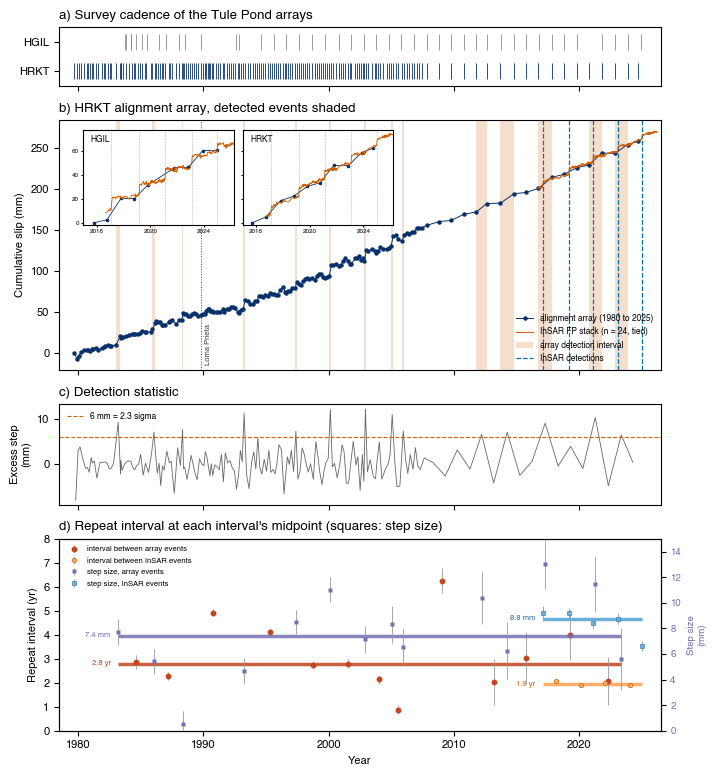

In [9]:
# [17]
fig, axes = plt.subplots(4, 1, figsize=(7.2, 7.8), sharex=True, height_ratios=[0.35, 1.5, 0.6, 1.15])

# a) survey cadence
ax = axes[0]
ax.eventplot([arrays["HGIL"].year.values, survey_yr], lineoffsets=[1, 0], linelengths=0.55, colors=["0.55", aa_color], lw=0.6)
ax.set_yticks([1, 0])
ax.set_yticklabels(["HGIL", "HRKT"])
ax.set_ylim(-0.5, 1.5)
ax.set_title("a) Survey cadence of the Tule Pond arrays", loc="left")

# b) the HRKT record with the detected events shaded and the InSAR onsets dashed
ax = axes[1]
hrkt_insar_dates, hrkt_insar_slip, hrkt_n_crossings = stacks[site]
ax.plot(survey_yr, cum_slip, "o", ms=2.2, color=aa_color, lw=0.7, ls="-", zorder=3,
        label=f"alignment array ({survey_yr.min():.0f} to {survey_yr.max():.0f})")
ax.plot(hrkt_insar_dates, hrkt_insar_slip, "-", lw=0.8, color=insar_color, zorder=5, label=f"InSAR FP stack (n = {hrkt_n_crossings}, tied)")
for event in hrkt_events.itertuples():
    ax.axvspan(event.onset_lo, event.onset_hi, color=insar_color, alpha=0.20, lw=0, zorder=1,
               label="array detection interval" if event.Index == 0 else None)
for i, onset in enumerate(insar_events.onset_yr):
    ax.axvline(onset, color=det_color, lw=0.9, ls="--", zorder=2, label="InSAR detections" if i == 0 else None)
ax.axvline(loma_prieta, color="0.25", lw=0.7, ls=":", zorder=2)
ax.text(loma_prieta + 0.35, 0.02, "Loma Prieta", transform=ax.get_xaxis_transform(), rotation=90, fontsize=5.5, color="0.25", va="bottom")
ax.set_ylabel("Cumulative slip (mm)")
ax.legend(fontsize=6, loc="lower right", frameon=False)
ax.set_title(f"b) {site} alignment array, detected events shaded", loc="left")
# two insets since zoom_t0 (HGIL and HRKT), each zeroed at its first survey, on one y range
zoom = {}
for code in ("HGIL", "HRKT"):
    array = arrays[code]
    insar_dates, insar_slip, n_crossings = stacks[code]
    recent = array[array.year >= zoom_t0]
    zoom[code] = (recent, insar_dates, insar_slip, float(recent.cum_mm.iloc[0]))
zoom_hi = max(max(float(np.nanmax(insar_slip)), float(recent.cum_mm.max())) - zero
              for recent, insar_dates, insar_slip, zero in zoom.values())
for i, code in enumerate(("HGIL", "HRKT")):
    recent, insar_dates, insar_slip, zero = zoom[code]
    inset = ax.inset_axes([0.04 + 0.265 * i, 0.58, 0.25, 0.38])
    inset.plot(recent.year, recent.cum_mm - zero, "o", ms=1.6, color=aa_color, lw=0.6, ls="-")
    inset.plot(insar_dates, insar_slip - zero, "-", lw=0.6, color=insar_color)
    for onset in insar_events.onset_yr:
        inset.axvline(onset, color="0.7", lw=0.4, ls="--", zorder=0)
    inset.set_xlim(zoom_t0, 2026.2)
    inset.set_ylim(-2, zoom_hi + 3)
    inset.set_xticks([2016, 2020, 2024])
    inset.tick_params(labelsize=4.5, length=1.5, pad=1.5)
    if i == 1:
        inset.set_yticklabels([])
    inset.text(0.05, 0.95, code, transform=inset.transAxes, fontsize=6, va="top")

# c) the detection statistic
ax = axes[2]
ax.plot(0.5 * (survey_yr[1:] + survey_yr[:-1]), excess, "-", lw=0.6, color="0.4")
ax.axhline(thr_mm, color=insar_color, lw=0.8, ls="--", label=f"{thr_mm:g} mm = {thr_mm / excess_sigma:.1f} sigma")
ax.set_ylabel("Excess step\n(mm)")
ax.legend(fontsize=6, loc="upper left", frameon=False)
ax.set_title("c) Detection statistic", loc="left")

# d) repeat intervals (left axis) and step sizes (right axis), medians as bars over each catalogue's span
ax = axes[3]
interval_median = dict(AA=float(np.median(aa_interval)), InSAR=float(np.median(insar_interval)))
step_median = dict(AA=float(hrkt_events.amplitude_mm.median()), InSAR=float(insar_events.amplitude_mm.median()))
aa_span = (float(hrkt_events.onset_yr.min()), float(hrkt_events.onset_yr.max()))
insar_span = (float(insar_events.onset_yr.min()), float(insar_events.onset_yr.max()))
c_interval_aa, c_interval_insar, c_step_aa, c_step_insar = "#C4441C", "#FDAE6B", "#7570B3", "#6BAED6"
ax.errorbar(aa_interval_mid, aa_interval, yerr=aa_interval_err, fmt="o", ms=3.2, color=c_interval_aa, ecolor="0.6", elinewidth=0.6, zorder=3,
            label="interval between array events")
ax.errorbar(insar_interval_mid, insar_interval, yerr=insar_interval_err, fmt="o", ms=3.2, mfc=c_interval_insar, mec="#D55E00", mew=0.5,
            ecolor="0.6", elinewidth=0.6, ls="none", zorder=3, label="interval between InSAR events")
ax.plot(aa_span, [interval_median["AA"]] * 2, "-", lw=2.5, color=c_interval_aa, alpha=0.85, zorder=2, solid_capstyle="butt")
ax.plot(insar_span, [interval_median["InSAR"]] * 2, "-", lw=2.5, color=c_interval_insar, zorder=2, solid_capstyle="butt")
ax.text(aa_span[0] - 0.6, interval_median["AA"], f"{interval_median['AA']:.1f} yr", fontsize=5.5, color=c_interval_aa, ha="right", va="center")
ax.text(insar_span[0] - 0.6, interval_median["InSAR"], f"{interval_median['InSAR']:.1f} yr", fontsize=5.5, color="#D55E00", ha="right", va="center")
ax_step = ax.twinx()
ax_step.errorbar(hrkt_events.onset_yr, hrkt_events.amplitude_mm, yerr=hrkt_events.amp_err, fmt="s", ms=3.2, mfc=c_step_aa, mec="none",
                 ecolor="0.6", elinewidth=0.6, ls="none", zorder=3, label="step size, array events")
ax_step.errorbar(insar_events.onset_yr, insar_events.amplitude_mm, yerr=insar_events.amp_err, fmt="s", ms=3.2, mfc=c_step_insar, mec="#2171B5",
                 mew=0.4, ecolor="0.6", elinewidth=0.6, ls="none", zorder=3, label="step size, InSAR events")
ax_step.plot(aa_span, [step_median["AA"]] * 2, "-", lw=2.5, color=c_step_aa, alpha=0.85, zorder=2, solid_capstyle="butt")
ax_step.plot(insar_span, [step_median["InSAR"]] * 2, "-", lw=2.5, color=c_step_insar, zorder=2, solid_capstyle="butt")
ax_step.text(aa_span[0] - 0.6, step_median["AA"], f"{step_median['AA']:.1f} mm", fontsize=5.5, color=c_step_aa, ha="right", va="center")
ax_step.text(insar_span[0] - 0.6, step_median["InSAR"], f"{step_median['InSAR']:.1f} mm", fontsize=5.5, color="#2171B5", ha="right", va="center")
ax_step.set_ylim(0, 15.0)
ax_step.set_ylabel("Step size\n(mm)", color="#7570B3", fontsize=7)
ax_step.tick_params(axis="y", labelcolor="#7570B3", labelsize=7)
ax.set_ylim(0, 8)
ax.set_ylabel("Repeat interval (yr)")
ax.set_xlabel("Year")
handles, labels = ax.get_legend_handles_labels()
handles_step, labels_step = ax_step.get_legend_handles_labels()
ax.legend(handles + handles_step, labels + labels_step, fontsize=5.5, loc="upper left", frameon=False)
ax.set_title("d) Repeat interval at each interval's midpoint (squares: step size)", loc="left")
ax.set_xlim(1978.5, 2026.5)
fig.tight_layout()
f_fig3 = os.path.join(fig_dir, f"fig3_aa_history_thr{thr_mm:g}mm_nev{len(hrkt_events)}.png")
fig.savefig(f_fig3, dpi=300)
fig.savefig(f_fig3.replace(".png", ".pdf"))
print("Saved Fig 3 to:", f_fig3)
plt.show()

## [18] Threshold sweep (supplement)

The same detector at the relative 3 sigma cut, at 6 mm and at 5 mm. The 3
sigma cut drops the 1986, 1988 and 1997 steps and its sparse catalogue implies
a steep interval-shortening trend that is a detection artefact; at 5 mm
sub-noise events (fitted amplitude < 2 mm) start padding the catalogue.

threshold 3 sigma = 8.2 mm:
      dropped 1993.18-1993.35: fitted slip -3.5 mm, not positive
      dropped 1993.18-1993.35: fitted slip -0.2 mm, not positive
threshold 6 mm:
      dropped 1988.29-1988.41: fitted slip -3.0 mm, not positive
threshold 5 mm:
       threshold  thr_mm  n_events  n_small  rate  trend_yr_per_decade
3 sigma = 8.2 mm    8.24         6        0  4.57                -3.30
            6 mm    6.00        14        1  3.41                -0.43
            5 mm    5.00        18        4  3.12                -0.25


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-28/figS_hrkt_threshold_sweep_3sig-6mm-5mm.png


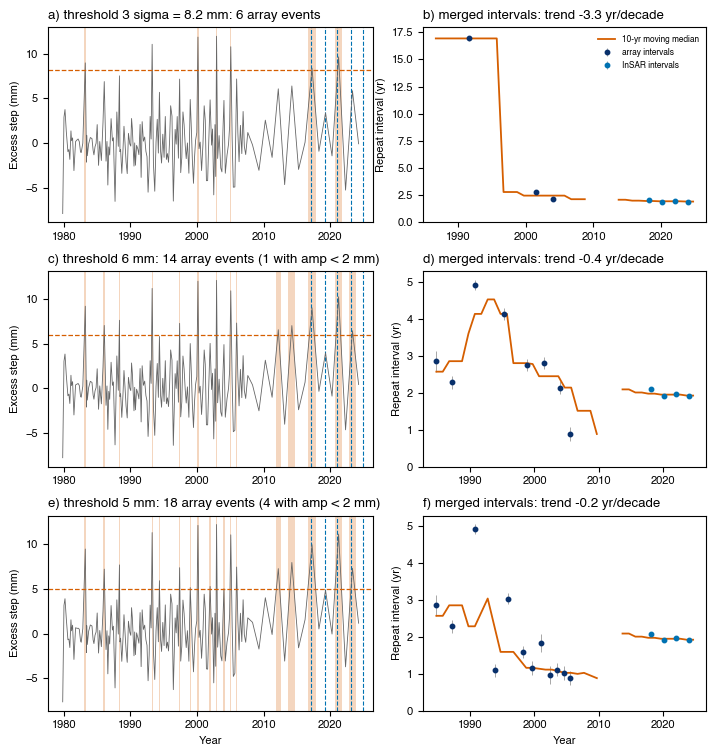

In [10]:
# [19]
# the robust sigma of the excess at the global rate sets the "3 sigma" case
global_rate = float(np.polyfit(survey_yr, cum_slip, 1)[0])
_, excess_global = detect_intervals(survey_yr, cum_slip, global_rate, 1e9)
sigma_global = utils.robust_sigma(excess_global)
cases = [(f"3 sigma = {3 * sigma_global:.1f} mm", 3 * sigma_global), ("6 mm", 6.0), ("5 mm", 5.0)]

fig, axes = plt.subplots(len(cases), 2, figsize=(7.2, 7.6), width_ratios=[1.15, 1.0])
sweep_rows = []
for i_case, (label, threshold_mm) in enumerate(cases):
    print(f"threshold {label}:")
    sweep_events, sweep_excess, sweep_rate, sweep_coef, sweep_G = run_detector(survey_yr, cum_slip, threshold_mm)
    sweep_merged = merge_catalogues(sweep_events, insar_events)
    interval_mid, interval, interval_err, has_insar = interval_series(sweep_merged)
    # the moving median of the merged intervals
    window_centres = np.arange(survey_yr.min() + win_yr / 2, sweep_merged.onset_yr.max() + 1e-9, win_step)
    window_median = []
    for centre in window_centres:
        in_window = np.abs(interval_mid - centre) <= win_yr / 2
        window_median.append(float(np.median(interval[in_window])) if in_window.sum() else np.nan)
    sweep_trend = np.polyfit(interval_mid, interval, 1)
    n_small = int((sweep_events.amplitude_mm < 2).sum())
    sweep_rows.append(dict(threshold=label, thr_mm=threshold_mm, n_events=len(sweep_events), n_small=n_small, rate=sweep_rate,
                           trend_yr_per_decade=sweep_trend[0] * 10))
    # left: the detection statistic with this threshold
    ax = axes[i_case, 0]
    ax.plot(0.5 * (survey_yr[1:] + survey_yr[:-1]), sweep_excess, "-", lw=0.6, color="0.4")
    ax.axhline(threshold_mm, color=insar_color, lw=0.9, ls="--")
    for event in sweep_events.itertuples():
        ax.axvspan(event.onset_lo, event.onset_hi, color=insar_color, alpha=0.25, lw=0)
    for onset in insar_events.onset_yr:
        ax.axvline(onset, color=det_color, lw=0.8, ls="--", zorder=1)
    ax.set_ylabel("Excess step (mm)")
    ax.set_title(f"{'ace'[i_case]}) threshold {label}: {len(sweep_events)} array events" + (f" ({n_small} with amp < 2 mm)" if n_small else ""), loc="left")
    # right: the merged repeat intervals and their moving median
    ax = axes[i_case, 1]
    ax.errorbar(interval_mid[~has_insar], interval[~has_insar], yerr=interval_err[~has_insar], fmt="o", ms=3.2, color=aa_color,
                ecolor="0.6", elinewidth=0.6, label="array intervals")
    ax.errorbar(interval_mid[has_insar], interval[has_insar], yerr=interval_err[has_insar], fmt="o", ms=3.2, mfc=det_color, mec=det_color,
                ecolor="0.6", elinewidth=0.6, ls="none", label="InSAR intervals")
    ax.plot(window_centres, window_median, "-", lw=1.3, color=insar_color, label=f"{win_yr:g}-yr moving median")
    ax.set_ylim(0, None)
    ax.set_ylabel("Repeat interval (yr)")
    ax.set_title(f"{'bdf'[i_case]}) merged intervals: trend {sweep_trend[0] * 10:+.1f} yr/decade", loc="left")
    if i_case == 0:
        ax.legend(fontsize=6, loc="upper right", frameon=False)
    if i_case == len(cases) - 1:
        axes[i_case, 0].set_xlabel("Year")
        ax.set_xlabel("Year")
fig.tight_layout()
sweep = pd.DataFrame(sweep_rows)
sweep.to_csv(os.path.join(out_dir, "hrkt_threshold_sweep.csv"), index=False)
print(sweep.round(2).to_string(index=False))
f_sweep = os.path.join(fig_dir, "figS_hrkt_threshold_sweep_3sig-6mm-5mm.png")
fig.savefig(f_sweep, dpi=300)
fig.savefig(f_sweep.replace(".png", ".pdf"))
print("Saved figure to:", f_sweep)
plt.show()

## [20] REGISTER

In [11]:
# [21]
stats_lines += [f"{site} EVENT HISTORY: record {survey_yr.min():.2f}-{survey_yr.max():.2f}, {len(survey_yr)} surveys, "
                f"median spacing {np.median(np.diff(survey_yr)) * 365.25:.0f} d",
                f"detection: fixed {thr_mm:g} mm excess per interval (= {thr_mm / excess_sigma:.1f} robust sigma, sigma {excess_sigma:.2f} mm); "
                f"joint model rate {inter_event_rate:.2f} mm/yr, annual {annual_mm:.2f} mm, rms {rms_mm:.2f} mm",
                f"{len(hrkt_events)} events, amplitudes {hrkt_events.amplitude_mm.min():.1f}-{hrkt_events.amplitude_mm.max():.1f} mm "
                f"(median {hrkt_events.amplitude_mm.median():.1f})"]
stats_lines += [f"  {event.onset_yr:8.3f} [{event.onset_lo:.2f}-{event.onset_hi:.2f}, {event.window_days:4.0f} d]  amp {event.amplitude_mm:5.1f} mm"
                for event in hrkt_events.itertuples()]
stats_lines += ["", f"repeat intervals: array only n {len(aa_interval)} median {np.median(aa_interval):.2f} yr; "
                f"InSAR n {len(insar_interval)} median {np.median(insar_interval):.2f} yr; "
                f"merged n {len(merged_interval)} median {np.median(merged_interval):.2f} yr, "
                f"halves {np.median(merged_interval[first_half]):.2f} / {np.median(merged_interval[~first_half]):.2f} yr, "
                f"trend {interval_trend[0] * 10:+.2f} yr/decade",
                f"step sizes: array median {hrkt_events.amplitude_mm.median():.1f} mm (n {len(hrkt_events)}); "
                f"InSAR median {insar_events.amplitude_mm.median():.1f} mm (n {len(insar_events)})",
                f"quiet interval {quiet_start:.2f}-{quiet_end:.2f} ({quiet_end - quiet_start:.1f} yr), {n_quiet} surveys, "
                f"largest step {max_step_quiet:.1f} mm, spans Loma Prieta {loma_prieta}",
                "", "threshold sweep:", sweep.round(2).to_string(index=False)]
sidecar = REG.sidecar("08_aa", stats_lines)

REG.register("08_hrkt_n_surveys", len(survey_yr), "count", 0, where="P9, M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_first_yr", survey_yr.min(), "decyear", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_last_yr", survey_yr.max(), "decyear", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_median_spacing_d", np.median(np.diff(survey_yr)) * 365.25, "d", 0, where="M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_sigma_mm", excess_sigma, "mm", 2, where="M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_threshold_sigma", thr_mm / excess_sigma, "1", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_rate_mm_yr", inter_event_rate, "mm/yr", 2, where="M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_annual_mm", annual_mm, "mm", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_n_events", len(hrkt_events), "count", 0, where="P9, M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_amp_min_mm", hrkt_events.amplitude_mm.min(), "mm", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_amp_max_mm", hrkt_events.amplitude_mm.max(), "mm", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_amp_median_mm", hrkt_events.amplitude_mm.median(), "mm", 1, where="P9", cell="detector", sidecar=sidecar)
REG.register("08_aa_interval_median_yr", np.median(aa_interval), "yr", 1, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_aa_interval_n", len(aa_interval), "count", 0, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_insar_interval_median_yr", np.median(insar_interval), "yr", 1, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_insar_step_median_mm", insar_events.amplitude_mm.median(), "mm", 1, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_merged_interval_median_yr", np.median(merged_interval), "yr", 2, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_merged_first_half_yr", np.median(merged_interval[first_half]), "yr", 2, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_merged_second_half_yr", np.median(merged_interval[~first_half]), "yr", 2, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_merged_trend_yr_per_decade", interval_trend[0] * 10, "yr/decade", 2, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_quiet_start_yr", quiet_start, "decyear", 2, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_quiet_end_yr", quiet_end, "decyear", 2, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_quiet_max_step_mm", max_step_quiet, "mm", 1, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_hrkt_dense_era_end_yr", 2007.84, "decyear", 2, where="M8", cell="detector", sidecar=sidecar)
for code in ("HGIL", "HRKT"):
    for kind in ("event_median", "quiet_median"):
        rows = aa_steps[(aa_steps.code == code) & (aa_steps.kind == kind)]
        if len(rows):
            REG.register(f"08_{code.lower()}_{kind}_mm", float(rows.step_mm.iloc[0]), "mm", 1, where="P9, Fig3", cell="arrays-insar", sidecar=sidecar)
for case in sweep.itertuples():
    REG.register(f"08_sweep_{case.thr_mm:.1f}mm_n_events", case.n_events, "count", 0, where="S threshold sweep", cell="sweep", sidecar=sidecar)
    REG.register(f"08_sweep_{case.thr_mm:.1f}mm_trend", case.trend_yr_per_decade, "yr/decade", 2, where="S threshold sweep", cell="sweep", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/08_alignment_arrays/08_aa_stats.txt
  registered 08_hrkt_n_surveys = 177 count  -> P9, M8


  registered 08_hrkt_first_yr = 1979.7 decyear  -> M8
  registered 08_hrkt_last_yr = 2024.7 decyear  -> M8
  registered 08_hrkt_median_spacing_d = 63 d  -> M8
  registered 08_hrkt_sigma_mm = 2.56 mm  -> M8


  registered 08_hrkt_threshold_sigma = 2.3 1  -> M8
  registered 08_hrkt_rate_mm_yr = 3.41 mm/yr  -> M8
  registered 08_hrkt_annual_mm = 1.7 mm  -> M8
  registered 08_hrkt_n_events = 14 count  -> P9, M8
  registered 08_hrkt_amp_min_mm = 0.5 mm  -> M8
  registered 08_hrkt_amp_max_mm = 13.0 mm  -> M8


  registered 08_hrkt_amp_median_mm = 7.4 mm  -> P9
  registered 08_aa_interval_median_yr = 2.8 yr  -> P9
  registered 08_aa_interval_n = 13 count  -> P9
  registered 08_insar_interval_median_yr = 1.9 yr  -> P9
  registered 08_insar_step_median_mm = 8.8 mm  -> P9


  registered 08_merged_interval_median_yr = 2.21 yr  -> P9
  registered 08_merged_first_half_yr = 2.82 yr  -> P9
  registered 08_merged_second_half_yr = 1.95 yr  -> P9
  registered 08_merged_trend_yr_per_decade = -0.43 yr/decade  -> P9
  registered 08_quiet_start_yr = 1988.41 decyear  -> P9
  registered 08_quiet_end_yr = 1993.18 decyear  -> P9


  registered 08_quiet_max_step_mm = 3.7 mm  -> P9
  registered 08_hrkt_dense_era_end_yr = 2007.84 decyear  -> M8
  registered 08_hgil_event_median_mm = 14.1 mm  -> P9, Fig3
  registered 08_hgil_quiet_median_mm = 0.4 mm  -> P9, Fig3
  registered 08_hrkt_event_median_mm = 12.0 mm  -> P9, Fig3
  registered 08_hrkt_quiet_median_mm = 3.8 mm  -> P9, Fig3


  registered 08_sweep_8.2mm_n_events = 6 count  -> S threshold sweep
  registered 08_sweep_8.2mm_trend = -3.30 yr/decade  -> S threshold sweep
  registered 08_sweep_6.0mm_n_events = 14 count  -> S threshold sweep
  registered 08_sweep_6.0mm_trend = -0.43 yr/decade  -> S threshold sweep
  registered 08_sweep_5.0mm_n_events = 18 count  -> S threshold sweep
  registered 08_sweep_5.0mm_trend = -0.25 yr/decade  -> S threshold sweep


Rendered registry to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt


'/Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt'